# Data Acquisition Demo

**Purpose**: fetch small samples from the real public sources described in Chapter 3 (a Common Crawl snapshot, robots.txt, and corpora hosted on the Hugging Face hub), look at what they contain, plan a token budget and mixture, and write a provenance manifest. Every claim is checked with an `assert`.

**Companion theory**: the [Data Acquisition and Sources chapter](../index.md).

**Network use**: each fetch is a few hundred kilobytes at most. If a source is unreachable the cell falls back to the committed samples in `data/`, so the notebook runs offline and its outputs are reproducible; a printed line says which path was taken.

**Dependencies**: only the Python standard library, NumPy and Matplotlib.

## 1. Setup

In [1]:
import gzip
import hashlib
import json
import math
import pathlib
import time
import urllib.error
import urllib.request
import urllib.robotparser
import zlib
from collections import Counter
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import numpy as np

DATA = pathlib.Path("data")            # committed fallback samples
UA = {"User-Agent": "llmatlas-notebook/0.1"}
FETCHED = []                             # provenance records, filled by every fetch


def fetch(url, headers=None, timeout=30, retries=2):
    """GET with a polite user agent, short timeout and a couple of retries. Raises on failure."""
    last = None
    for attempt in range(retries + 1):
        try:
            req = urllib.request.Request(url, headers={**UA, **(headers or {})})
            t0 = time.time()
            data = urllib.request.urlopen(req, timeout=timeout).read()
            FETCHED.append({"url": url, "bytes": len(data), "seconds": round(time.time() - t0, 2),
                            "sha256": hashlib.sha256(data).hexdigest(), "live": True})
            return data
        except (urllib.error.URLError, TimeoutError, ConnectionError) as e:
            last = e
            time.sleep(1 + attempt)
    raise last


def fetch_or_fallback(url, fallback_path, headers=None, parse=lambda b: b):
    """Try the network; on failure read the committed sample and say so."""
    try:
        data = parse(fetch(url, headers))
        print(f"live:     {url[:80]}")
        return data, "live"
    except Exception as e:  # noqa: BLE001 - any network failure means use the sample
        raw = pathlib.Path(fallback_path).read_bytes()
        FETCHED.append({"url": url, "bytes": len(raw), "seconds": 0.0,
                        "sha256": hashlib.sha256(raw).hexdigest(), "live": False, "fallback": str(fallback_path)})
        print(f"fallback: {url[:60]} ({type(e).__name__}) -> {fallback_path}")
        return None, "fallback"


print("data directory:", DATA.resolve())
assert DATA.is_dir(), "run the notebook from its own directory so that data/ is found"

data directory: /mnt/ztank/development/Projects/llmatlas-public/.claude/worktrees/chapter-data-acquisition/chapters/03-data-acquisition/examples/data


(nb-acq-crawl)=
## 2. A Slice of a Common Crawl Snapshot

A snapshot lists its files in `warc.paths.gz`; each WARC file is a sequence of gzip members, one per record. A byte-range request on the first file is enough to read a few dozen records without downloading a gigabyte.

In [2]:
CRAWL = "CC-MAIN-2026-39"
BASE = "https://data.commoncrawl.org/"


def warc_records(blob):
    """Split concatenated gzip members into complete WARC records (the last member is usually cut off)."""
    records, pos = [], 0
    while pos < len(blob):
        d = zlib.decompressobj(16 + zlib.MAX_WBITS)
        try:
            chunk = d.decompress(blob[pos:])
        except zlib.error:
            break
        if not d.eof:
            break
        records.append(chunk)
        pos = len(blob) - len(d.unused_data)
    return records


def parse_record(record):
    head, _, payload = record.partition(b"\r\n\r\n")
    lines = head.decode("utf-8", "replace").splitlines()
    headers = dict(line.split(": ", 1) for line in lines[1:] if ": " in line)
    return headers, payload


# Manifest
paths, how = fetch_or_fallback(f"{BASE}crawl-data/{CRAWL}/warc.paths.gz", DATA / "cc_manifest.json",
                               parse=lambda b: gzip.decompress(b).decode().splitlines())
if paths is None:
    manifest = json.loads((DATA / "cc_manifest.json").read_text())
    paths = manifest["first_paths"]
    num_files = manifest["num_warc_files"]
else:
    num_files = len(paths)
print(f"{CRAWL}: {num_files:,} WARC files; first: {paths[0]}")
assert num_files >= 50_000, "a monthly snapshot has on the order of 100,000 WARC files"
assert paths[0].startswith(f"crawl-data/{CRAWL}/segments/")

# First 256 KB of the first WARC file
raw, how = fetch_or_fallback(BASE + paths[0], DATA / "cc_warc_slice.json", headers={"Range": "bytes=0-262143"})
if raw is not None:
    records = [parse_record(r) for r in warc_records(raw)]
    records = [(h, p[:1500], len(p)) for h, p in records]
else:
    slice_ = json.loads((DATA / "cc_warc_slice.json").read_text())
    records = []
    for r in slice_["records"]:
        hdrs = dict(l.split(": ", 1) for l in r["headers"].splitlines()[1:] if ": " in l)
        records.append((hdrs, r["payload_prefix"].encode("utf-8"), r["payload_bytes"]))

types = Counter(h.get("WARC-Type") for h, _, _ in records)
print(f"{len(records)} complete records in 256 KB:", dict(types))
assert {"request", "response", "metadata"} <= set(types), "each fetched page yields request, response and metadata records"
assert abs(types["request"] - types["response"]) <= 1, "one request record per response record (the slice may cut between a pair)"
assert all(h.get("WARC-Target-URI") for h, _, _ in records if h.get("WARC-Type") == "response")

payload_types = Counter(h.get("WARC-Identified-Payload-Type", "?") for h, _, _ in records if h.get("WARC-Type") == "response")
print("declared payload types of responses:", dict(payload_types))

# One page, as the crawler saw it: HTTP status line, headers, then HTML
hdr, payload, n = next((h, p, n) for h, p, n in records if h.get("WARC-Type") == "response")
print(f"\n{hdr['WARC-Target-URI']}  ({n:,} payload bytes, fetched {hdr['WARC-Date']})")
print(payload[:700].decode("utf-8", "replace"))

live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/warc.paths.gz
CC-MAIN-2026-39: 100,000 WARC files; first: crawl-data/CC-MAIN-2026-39/segments/1788492699475.64/warc/CC-MAIN-20260904131603-20260904161603-00000.warc.gz
live:     https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/1788492699475.6
62 complete records in 256 KB: {'warcinfo': 1, 'request': 21, 'response': 20, 'metadata': 20}
declared payload types of responses: {'application/xhtml+xml': 5, 'text/html': 15}

http://0014xxx.com/28/index.html  (47,108 payload bytes, fetched 2026-09-04T14:43:16Z)
HTTP/1.1 200 OK
Server: nginx
Date: Fri, 04 Sep 2026 14:43:16 GMT
Content-Type: text/html
Last-Modified: Thu, 03 Sep 2026 17:18:44 GMT
X-Crawler-Transfer-Encoding: chunked
Connection: keep-alive
Vary: Accept-Encoding
ETag: W/"6a99abf4-b5f6"
Strict-Transport-Security: max-age=31536000
Alt-Svc: quic=":443"; h3=":443"; h3-29=":443"; h3-27=":443";h3-25=":443"; h3-T050=":443"; h3-Q050=":443";h3-Q049=":443";h3-Q0

In [3]:
# Order-of-magnitude size of a snapshot from the slice: mean compressed bytes per record x records
# per file (a WARC file is ~1 GB) x files. The first records of a file are small (the crawler
# starts each file with short pages), so this over-estimates the page count by a factor of two or
# three; Common Crawl's own figure for a recent snapshot is two to three billion pages.
bytes_per_record = 262_144 / max(1, len(records))
records_per_file = 1.0e9 / bytes_per_record
pages_per_file = records_per_file / 3           # request + response + metadata per page
est_pages = pages_per_file * num_files
print(f"~{bytes_per_record:,.0f} compressed bytes per record -> ~{pages_per_file:,.0f} pages per WARC file "
      f"-> ~{est_pages/1e9:.0f} billion pages (upper estimate; published figure is 2-3 billion)")
assert 1e9 < est_pages < 1e10, "the estimate should land within an order of magnitude of a few billion pages"

~4,228 compressed bytes per record -> ~78,837 pages per WARC file -> ~8 billion pages (upper estimate; published figure is 2-3 billion)


(nb-acq-robots)=
## 3. What robots.txt Allows

The Robots Exclusion Protocol is the mechanism through which sites consent to, or refuse, crawling. Wikipedia's file is one of the most detailed on the web. The user agents below are the ones that matter for training data.

In [4]:
robots_bytes, how = fetch_or_fallback("https://en.wikipedia.org/robots.txt", DATA / "wikipedia_robots.txt")
if robots_bytes is None:
    robots_bytes = (DATA / "wikipedia_robots.txt").read_bytes()
robots_text = robots_bytes.decode("utf-8", "replace")

rp = urllib.robotparser.RobotFileParser()
rp.parse(robots_text.splitlines())

AGENTS = ["*", "CCBot", "GPTBot", "ClaudeBot", "Google-Extended", "Bytespider", "PerplexityBot"]
pages = {
    "article": "https://en.wikipedia.org/wiki/Language_model",
    "search": "https://en.wikipedia.org/w/index.php?title=Special:Search&search=x",
    "history": "https://en.wikipedia.org/w/index.php?title=Language_model&action=history",
}
print(f"{'agent':16}" + "".join(f"{k:>10}" for k in pages) + "   crawl-delay")
decisions = {}
for agent in AGENTS:
    decisions[agent] = {k: rp.can_fetch(agent, u) for k, u in pages.items()}
    print(f"{agent:16}" + "".join(f"{str(v):>10}" for v in decisions[agent].values()) + f"   {rp.crawl_delay(agent)}")

# Count explicit rule groups and Disallow lines per named agent in the raw file
groups = Counter()
current = []
for line in robots_text.splitlines():
    key, _, value = line.partition(":")
    key, value = key.strip().lower(), value.strip()
    if key == "user-agent":
        current = [value]
    elif key == "disallow" and current:
        groups[current[0]] += 1
print("\nDisallow lines per user-agent group (top 8):", groups.most_common(8))

assert decisions["*"]["article"], "articles are open to everyone"
assert not decisions["*"]["search"], "search result pages are disallowed for everyone"
assert sum(groups.values()) > 100, "Wikipedia's robots.txt carries hundreds of rules"
assert groups["*"] > 50

live:     https://en.wikipedia.org/robots.txt
agent              article    search   history   crawl-delay
*                     True     False     False   None
CCBot                 True     False     False   None
GPTBot                True     False     False   None
ClaudeBot             True     False     False   None
Google-Extended       True     False     False   None
Bytespider            True     False     False   None
PerplexityBot         True     False     False   None

Disallow lines per user-agent group (top 8): [('*', 428), ('MJ12bot', 1), ('Mediapartners-Google*', 1), ('IsraBot', 1), ('Orthogaffe', 1), ('UbiCrawler', 1), ('DOC', 1), ('Zao', 1)]


(nb-acq-sources)=
## 4. Comparing Sources Through the Hugging Face Rows API

The datasets-server `rows` endpoint returns a page of a hosted dataset as JSON without downloading it, which is enough to see how FineWeb, FineWeb-Edu, C4, Wikipedia and FineWeb-2 differ. Text is truncated to 1,200 characters in the fallback files, so lengths are measured in words of the available excerpt and compared across sources, not quoted as document lengths.

In [5]:
SOURCES = {
    "fineweb":      ("HuggingFaceFW/fineweb", "sample-10BT", 100),
    "fineweb_edu":  ("HuggingFaceFW/fineweb-edu", "sample-10BT", 100),
    "c4":           ("allenai/c4", "en", 100),
    "wikipedia":    ("wikimedia/wikipedia", "20231101.en", 50),
    "fineweb2_fra": ("HuggingFaceFW/fineweb-2", "fra_Latn", 50),
}
ROWS = "https://datasets-server.huggingface.co/rows?dataset={}&config={}&split=train&offset=0&length={}"

samples = {}
for name, (dataset, config, n) in SOURCES.items():
    data, how = fetch_or_fallback(ROWS.format(dataset, config, n), DATA / f"hf_{name}.json",
                                  parse=lambda b: [r["row"] for r in json.loads(b)["rows"]])
    if data is None:
        data = json.loads((DATA / f"hf_{name}.json").read_text())["rows"]
    for r in data:
        r["text"] = r["text"][:1200]       # same truncation as the committed samples
    samples[name] = data
    assert len(data) == n, (name, len(data))

print({k: sorted(v[0].keys()) for k, v in samples.items()})

live:     https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fineweb&config


live:     https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fineweb-edu&co


live:     https://datasets-server.huggingface.co/rows?dataset=allenai/c4&config=en&split=t


live:     https://datasets-server.huggingface.co/rows?dataset=wikimedia/wikipedia&config=2


live:     https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fineweb-2&conf
{'fineweb': ['date', 'dump', 'file_path', 'id', 'language', 'language_score', 'text', 'token_count', 'url'], 'fineweb_edu': ['dump', 'file_path', 'id', 'int_score', 'language', 'language_score', 'score', 'text', 'token_count', 'url'], 'c4': ['text', 'timestamp', 'url'], 'wikipedia': ['id', 'text', 'title', 'url'], 'fineweb2_fra': ['date', 'dump', 'file_path', 'id', 'language', 'language_score', 'language_script', 'minhash_cluster_size', 'text', 'top_langs', 'url']}


In [6]:
def stats(rows):
    words = [len(r["text"].split()) for r in rows]
    ttr = [len(set(r["text"].lower().split())) / max(1, len(r["text"].split())) for r in rows]
    return {"docs": len(rows), "median_words": float(np.median(words)), "type_token_ratio": float(np.mean(ttr))}

print(f"{'source':14}{'docs':>6}{'median words':>14}{'TTR':>8}")
for name, rows in samples.items():
    s = stats(rows)
    print(f"{name:14}{s['docs']:>6}{s['median_words']:>14.0f}{s['type_token_ratio']:>8.2f}")

# FineWeb keeps pages with a fastText English score of at least 0.65; the field is in every row.
scores = [r["language_score"] for r in samples["fineweb"]]
assert all(r["language"] == "en" for r in samples["fineweb"])
assert min(scores) >= 0.65, f"FineWeb's language threshold is 0.65; got {min(scores):.3f}"
assert all(r["language"] == "fra" for r in samples["fineweb2_fra"])

# FineWeb-Edu's sample keeps documents the educational-value classifier scored >= 3 of 5.
edu = [r["int_score"] for r in samples["fineweb_edu"]]
print("\nFineWeb-Edu int_score distribution:", dict(sorted(Counter(edu).items())))
assert min(edu) >= 3, "FineWeb-Edu keeps score >= 3"

# Domains: how concentrated is each web source on a handful of hosts?
def top_domains(rows, k=5):
    hosts = Counter(urlparse(r["url"]).netloc.removeprefix("www.") for r in rows if r.get("url"))
    return hosts.most_common(k)

for name in ("fineweb", "fineweb_edu", "c4", "fineweb2_fra"):
    print(f"{name:14}", top_domains(samples[name]))

source          docs  median words     TTR
fineweb          100           187    0.69
fineweb_edu      100           190    0.66
c4               100           180    0.69
wikipedia         50           192    0.63
fineweb2_fra      50           184    0.70

FineWeb-Edu int_score distribution: {3: 79, 4: 20, 5: 1}
fineweb        [('daytimeroyaltyonline.com', 1), ('endogenousretrovirus.blogspot.com', 1), ('news.cancerconnect.com', 1), ('sharingsolution.com', 1), ('supermarketnews.com', 1)]
fineweb_edu    [('phys.org', 2), ('everything2.com', 2), ('britannica.com', 2), ('austenauthors.net', 1), ('query.nytimes.com', 1)]
c4             [('klyq.com', 1), ('forums.macrumors.com', 1), ('awishcometrue.com', 1), ('blackhatworld.com', 1), ('bond.dpsk12.org', 1)]
fineweb2_fra   [('abeillenoireouessant.fr', 1), ('accessories.dell.com', 1), ('armeniantrends.blogspot.com', 1), ('auto.vlan.be', 1), ('bapoumba.wordpress.com', 1)]


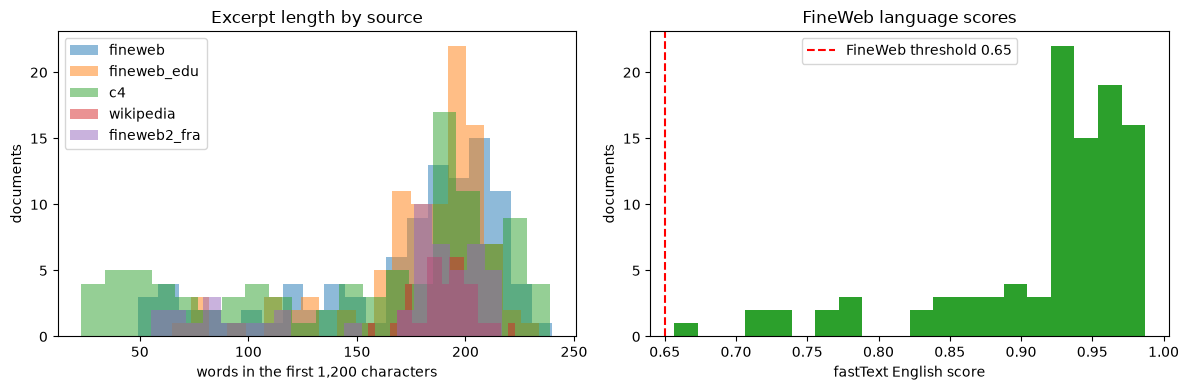

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, rows in samples.items():
    axes[0].hist([len(r["text"].split()) for r in rows], bins=20, alpha=0.5, label=name)
axes[0].set_xlabel("words in the first 1,200 characters"); axes[0].set_ylabel("documents"); axes[0].legend(); axes[0].set_title("Excerpt length by source")
axes[1].hist(scores, bins=20, color="tab:green"); axes[1].axvline(0.65, color="r", ls="--", label="FineWeb threshold 0.65")
axes[1].set_xlabel("fastText English score"); axes[1].set_ylabel("documents"); axes[1].legend(); axes[1].set_title("FineWeb language scores")
plt.tight_layout(); plt.show()

(nb-acq-mixture)=
## 5. From a Compute Budget to a Mixture

Chapter 2 gives $C \approx 6ND$ and the Chinchilla optimum $D \approx 20N$. Chapter 3 adds the epoch constraint $w_s D / U_s \le 4$ per source. `plan_mixture` is the chapter's function; here it is run over a realistic source table and then under the 25% loss of web text that the consent study measured.

In [8]:
def plan_mixture(total_tokens, sources, max_epochs=4.0):
    caps = {s: min(1.0, max_epochs * u / total_tokens) for s, (u, _) in sources.items()}
    if sum(caps.values()) < 1.0:
        raise ValueError("not enough unique data for this budget at this epoch cap")
    weights = {s: w for s, (_, w) in sources.items()}
    total = sum(weights.values())
    weights = {s: w / total for s, w in weights.items()}
    clipped = set()
    while True:
        over = {s for s in weights if s not in clipped and weights[s] > caps[s] + 1e-12}
        if not over:
            break
        surplus = sum(weights[s] - caps[s] for s in over)
        for s in over:
            weights[s] = caps[s]
        clipped |= over
        free = {s: weights[s] for s in weights if s not in clipped}
        scale = sum(free.values())
        for s in free:
            weights[s] += surplus * free[s] / scale
    return {s: (weights[s], weights[s] * total_tokens, weights[s] * total_tokens / sources[s][0]) for s in sources}


# Budget: an 8B model at 1e24 FLOPs, trained past the Chinchilla point as production models are
C, N = 1e24, 8e9
D = C / (6 * N)
N_chin = math.sqrt(C / 120)
print(f"budget {C:.0e} FLOPs, N = {N/1e9:.0f}B  ->  D = {D/1e12:.1f}T tokens ({D/N:.0f} per parameter);"
      f" Chinchilla-optimal would be N* = {N_chin/1e9:.0f}B with D* = {20*N_chin/1e12:.1f}T")
assert abs(6 * N * D / C - 1) < 1e-9

sources = {              # unique tokens after cleaning, preferred share
    "web":       (15e12,    0.80),
    "code":      (1.0e12,   0.08),
    "papers":    (0.15e12,  0.04),
    "wikipedia": (0.0045e12, 0.03),
    "books":     (0.03e12,  0.03),
    "dialogue":  (0.05e12,  0.02),
}
plan = plan_mixture(D, sources)
print(f"\n{'source':10}{'weight':>8}{'tokens':>10}{'epochs':>8}")
for s, (w, t, e) in plan.items():
    print(f"{s:10}{w:8.3f}{t/1e12:9.2f}T{e:8.2f}")
assert abs(sum(w for w, _, _ in plan.values()) - 1) < 1e-9
assert all(e <= 4 + 1e-9 for _, _, e in plan.values())
assert plan["wikipedia"][2] == 4.0 and plan["books"][2] == 4.0, "the small sources are pinned at the epoch cap"

budget 1e+24 FLOPs, N = 8B  ->  D = 20.8T tokens (2604 per parameter); Chinchilla-optimal would be N* = 91B with D* = 1.8T

source      weight    tokens  epochs
web          0.868    18.09T    1.21
code         0.087     1.81T    1.81
papers       0.029     0.60T    4.00
wikipedia    0.001     0.02T    4.00
books        0.006     0.12T    4.00
dialogue     0.010     0.20T    4.00


web epochs: 1.21 -> 1.61 after losing 25% of unique web text


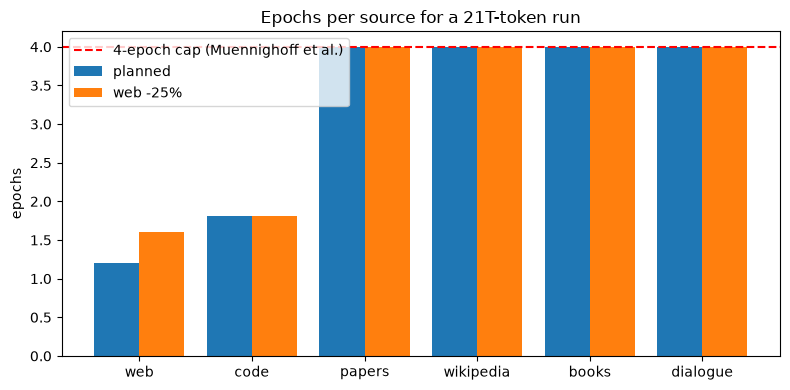

In [9]:
# The consent study: ~25% of the highest-quality web tokens became off limits within a year.
shrunk = dict(sources); shrunk["web"] = (sources["web"][0] * 0.75, sources["web"][1])
plan_shrunk = plan_mixture(D, shrunk)
print(f"web epochs: {plan['web'][2]:.2f} -> {plan_shrunk['web'][2]:.2f} after losing 25% of unique web text")
assert plan_shrunk["web"][2] > plan["web"][2]

fig, ax = plt.subplots(figsize=(8, 4))
names = list(sources)
ax.bar([i - 0.2 for i in range(len(names))], [plan[s][2] for s in names], 0.4, label="planned")
ax.bar([i + 0.2 for i in range(len(names))], [plan_shrunk[s][2] for s in names], 0.4, label="web -25%")
ax.axhline(4, color="r", ls="--", label="4-epoch cap (Muennighoff et al.)")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names); ax.set_ylabel("epochs"); ax.legend()
ax.set_title(f"Epochs per source for a {D/1e12:.0f}T-token run")
plt.tight_layout(); plt.show()

(nb-acq-provenance)=
## 6. A Provenance Manifest

Every fetch above was recorded with its URL, size and SHA-256. The manifest is what accompanies the raw data into Chapter 4; the hash check against the committed samples shows that the record identifies the exact bytes.

In [10]:
def provenance_record(source, locator, raw_bytes, licence, robots_decision, synthetic=False, **extra):
    return {"source": source, "locator": locator, "sha256": hashlib.sha256(raw_bytes).hexdigest(),
            "bytes": len(raw_bytes), "fetched_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
            "licence": licence, "robots": robots_decision, "synthetic": synthetic, **extra}


LICENCES = {
    "data.commoncrawl.org": "Common Crawl terms of use",
    "en.wikipedia.org": "CC BY-SA 4.0",
    "datasets-server.huggingface.co": "per dataset: ODC-BY (FineWeb, FineWeb-Edu, FineWeb-2), ODC-BY (C4), CC BY-SA (Wikipedia); sources' terms apply",
}
manifest = []
for f in FETCHED:
    host = urlparse(f["url"]).netloc
    rec = provenance_record(host, f["url"], b"", LICENCES.get(host, "unknown"),
                            "allowed:*" if host != "en.wikipedia.org" else f"allowed:*={decisions['*']['article']}",
                            live=f["live"], bytes=f["bytes"], sha256=f["sha256"])
    manifest.append(rec)

# The committed samples are content-addressed: hashing the file on disk reproduces the manifest hash.
on_disk = (DATA / "wikipedia_robots.txt").read_bytes()
robots_recs = [m for m in manifest if "robots.txt" in m["locator"]]
assert robots_recs, "robots.txt fetch was recorded"
if not robots_recs[-1]["live"]:
    assert robots_recs[-1]["sha256"] == hashlib.sha256(on_disk).hexdigest()
assert all(len(m["sha256"]) == 64 for m in manifest)
assert len(manifest) >= 8, "manifest, WARC slice, robots.txt and five datasets"

live = sum(m["live"] for m in manifest)
print(f"{len(manifest)} records, {live} live fetches, {len(manifest) - live} from committed samples\n")
for m in manifest:
    print(f"{m['sha256'][:12]}  {m['bytes']:>8,} B  {'live' if m['live'] else 'file'}  {m['locator'][:70]}")

8 records, 8 live fetches, 0 from committed samples

3742ee3efd21   201,289 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/warc.paths.gz
94bb75fa4731   262,144 B  live  https://data.commoncrawl.org/crawl-data/CC-MAIN-2026-39/segments/17884
48b98d80c844    28,275 B  live  https://en.wikipedia.org/robots.txt
dd8e3594cfc2   334,240 B  live  https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fine
a4eeea6d8ea2   419,904 B  live  https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fine
0ad5a4995cac   220,842 B  live  https://datasets-server.huggingface.co/rows?dataset=allenai/c4&config=
f105e3ca4f87  1,657,633 B  live  https://datasets-server.huggingface.co/rows?dataset=wikimedia/wikipedi
a388c205fa69   270,639 B  live  https://datasets-server.huggingface.co/rows?dataset=HuggingFaceFW/fine


## Summary

- A Common Crawl snapshot is about 100,000 WARC files; a byte-range request reads records from one without downloading it, and every fetched page yields request, response and metadata records.
- robots.txt is parsed by the standard library; Wikipedia opens articles to every agent and closes search and history pages, with hundreds of explicit rules.
- The hosted corpora differ visibly in a hundred-document sample: FineWeb's language scores all clear its 0.65 threshold, FineWeb-Edu's sample is entirely score 3 or above, and the sources differ in excerpt length and vocabulary.
- An 8B model at $10^{24}$ FLOPs needs about 20T tokens; the small, high-quality sources hit the four-epoch cap first and their surplus flows to the web portion, which loses a quarter of its unique text under current opt-out trends.
- Every fetch has a content hash and a licence note, which is the minimum that must travel with the data into Chapter 4.

For the reasoning behind each step, return to the [Data Acquisition and Sources chapter](../index.md).